# 02 · Data preparation

This notebook turns the raw tables into a leakage-safe modeling table for the two tasks in `docs/prd.md`: **(a)** the final regular-season ranking (regression of points per game, then sorting) and **(b)** in-season coach change (binary classification). It follows the adopted decisions: NHL only, predictions made the day before the season starts, **2009 is the final test season**, 2005–2008 are validation seasons, and earlier seasons are training data.

Raw CSVs are never modified; corrections live in derived copies. Small Ridge and logistic pipelines appear only in step 9, to choose the training era. Two rubric items are deliberately deferred to the modeling notebook because they must be fitted inside each training fold: **class-imbalance resampling** and **feature selection**.

| Step | Purpose |
|---|---|
| 1 | Load tables into a DuckDB database for SQL work |
| 2 | Data quality in six dimensions |
| 3 | Integrate seven sources into one profile per team-season |
| 4 | Engineer prior-season and opening-day coach features; build targets |
| 5 | Rescale within each season; discretize coach tenure |
| 6 | Detect, discuss and treat outliers |
| 7 | Explain missing values and compare imputation methods |
| 8 | Remove redundant features |
| 9 | Grow the development sample and choose the training era |
| 10 | Export the modeling table and feature dictionary |

## 1. Load the tables into a database

**What we want to do:** Read the 22 CSVs unchanged and expose each one to an in-memory DuckDB database, so cross-table checks and aggregations can be written as SQL.

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import duckdb
from IPython.display import display
ROOT = Path.cwd().resolve()
if not (ROOT / 'hockey_development_data').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'hockey_development_data').is_dir(), 'Run from project root or notebooks/'
os.environ['MPLCONFIGDIR'] = str(ROOT / '.mplconfig')
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)
DATA = ROOT / 'hockey_development_data'
OUT = ROOT / 'reports' / 'prep'
OUT.mkdir(parents=True, exist_ok=True)
PROCESSED = ROOT / 'data' / 'processed'
PROCESSED.mkdir(parents=True, exist_ok=True)
raw = {p.stem: pd.read_csv(p) for p in sorted(DATA.glob('*.csv'))}
assert len(raw) == 22
# In-memory DuckDB database: each raw DataFrame is exposed as a read-only SQL view.
con = duckdb.connect()
for name, df in raw.items():
    con.register(name, df)
def sql(query):
    return con.sql(query).df()
TEST_YEAR = 2009
VALIDATION_YEARS = [2005, 2006, 2007, 2008]
print(f'{len(raw)} tables registered in DuckDB {duckdb.__version__}; pandas {pd.__version__}.')
display(sql("SELECT lgID, count(*) AS team_seasons, min(year) AS first_year, max(year) AS last_year FROM Teams GROUP BY lgID ORDER BY team_seasons DESC"))

22 tables registered in DuckDB 2.0.0; pandas 3.1.0.


,lgID,team_seasons,first_year,last_year
0,NHL,1265,1917,2009
1,WHA,84,1972,1978
2,NHA,45,1909,1916
3,PCHA,41,1911,1923
4,WCHL,24,1921,1925


**What we got:** All 22 tables are queryable with SQL. NHL has 1,265 team-seasons from 1917 to 2009; WHA (1972–1978), NHA, PCHA and WCHL are historical leagues that end long before the test season, which supports the NHL-only decision.

## 2. Data quality in six dimensions

**What we want to do:** Measure **completeness, uniqueness, validity, consistency, accuracy and timeliness** with explicit rules. Each rule reports the rows checked and the violations. Checks focus on the NHL from 1967, the period the models will use (step 9). Accuracy is tested by reconciling independent sources that describe the same quantity.

In [2]:
checks = []
def check(dimension, description, query):
    checked, violations = con.execute(query).fetchall()[0]
    checks.append(dict(dimension=dimension, check=description, rows_checked=int(checked),
                       violations=int(violations), violation_rate=round(violations / checked, 4) if checked else None))
def modern(alias=''):
    a = alias + '.' if alias else ''
    return f"{a}lgID = 'NHL' AND {a}year >= 1967"
# Completeness
check('completeness', 'Teams special-teams fields (PPG, PPC, PKG, PKC) present, NHL 1967+',
      f"SELECT count(*), count(*) FILTER (WHERE PPG IS NULL OR PPC IS NULL OR PKG IS NULL OR PKC IS NULL) FROM Teams WHERE {modern()}")
check('completeness', 'Goalies shots against (SA) present, NHL 1967+',
      f"SELECT count(*), count(*) FILTER (WHERE SA IS NULL) FROM Goalies WHERE {modern()}")
check('completeness', 'Goalies shots against (SA) present, NHL 1983+',
      "SELECT count(*), count(*) FILTER (WHERE SA IS NULL) FROM Goalies WHERE lgID = 'NHL' AND year >= 1983")
check('completeness', 'Master birthYear present for NHL skaters 1967+',
      f"SELECT count(*), count(*) FILTER (WHERE m.birthYear IS NULL) FROM Scoring s LEFT JOIN Master m USING (playerID) WHERE {modern('s')}")
# Uniqueness
for table, key in [('Teams', 'year, lgID, tmID'), ('Coaches', 'coachID, year, tmID, stint'),
                   ('Scoring', 'playerID, year, stint'), ('Goalies', 'playerID, year, stint')]:
    check('uniqueness', f'{table} key ({key}) has no duplicates',
          f"SELECT (SELECT count(*) FROM {table}), (SELECT coalesce(sum(n - 1), 0) FROM (SELECT count(*) AS n FROM {table} GROUP BY {key} HAVING n > 1))")
check('uniqueness', 'One NHL row per (year, franchID)',
      "SELECT (SELECT count(*) FROM Teams WHERE lgID = 'NHL'), (SELECT coalesce(sum(n - 1), 0) FROM (SELECT count(*) AS n FROM Teams WHERE lgID = 'NHL' GROUP BY year, franchID HAVING n > 1))")
# Validity
check('validity', 'Teams counts non-negative and W + L <= G, NHL 1967+',
      f"SELECT count(*), count(*) FILTER (WHERE least(G, W, L, GF, GA, Pts) < 0 OR W + L > G) FROM Teams WHERE {modern()}")
check('validity', 'Power-play goals <= opportunities; PK goals against <= times shorthanded',
      f"SELECT count(*), count(*) FILTER (WHERE PPG > PPC OR PKG > PKC) FROM Teams WHERE {modern()}")
check('validity', 'Goalie GA <= SA where SA is recorded',
      "SELECT count(*), count(*) FILTER (WHERE GA > SA) FROM Goalies WHERE lgID = 'NHL' AND SA IS NOT NULL")
check('validity', 'Player games (Scoring.GP) <= team games (Teams.G), NHL 1967+',
      f"SELECT count(*), count(*) FILTER (WHERE s.GP > t.G) FROM Scoring s JOIN Teams t USING (year, lgID, tmID) WHERE {modern('t')}")
check('validity', 'Player birth year plausible (1850-1995)',
      "SELECT count(*), count(*) FILTER (WHERE birthYear < 1850 OR birthYear > 1995) FROM Master WHERE playerID IS NOT NULL AND birthYear IS NOT NULL")
# Consistency (internal identities and cross-table agreement)
check('consistency', 'G = W + L + T + OTL (blank T/OTL as 0), NHL 1967+',
      f"SELECT count(*), count(*) FILTER (WHERE G <> W + L + coalesce(T, 0) + coalesce(OTL, 0)) FROM Teams WHERE {modern()}")
check('consistency', 'Pts = 2W + T + OTL (blank T/OTL as 0), NHL 1967+',
      f"SELECT count(*), count(*) FILTER (WHERE Pts <> 2 * W + coalesce(T, 0) + coalesce(OTL, 0)) FROM Teams WHERE {modern()}")
check('consistency', 'Division rank never puts a lower-points team above a higher-points one, NHL 1967+ (team pairs)',
      f"""SELECT count(*), count(*) FILTER (WHERE (a.Pts > b.Pts AND a.rank > b.rank) OR (a.Pts < b.Pts AND a.rank < b.rank))
          FROM Teams a JOIN Teams b ON a.year = b.year AND a.lgID = b.lgID AND a.divID = b.divID AND a.tmID < b.tmID
          WHERE {modern('a')}""")
check('consistency', 'Sum of coach regular-season games = team games, NHL 1967+',
      f"""SELECT count(*), count(*) FILTER (WHERE c.g <> t.G) FROM Teams t
          JOIN (SELECT year, lgID, tmID, sum(g) AS g FROM Coaches GROUP BY ALL) c USING (year, lgID, tmID) WHERE {modern('t')}""")
# Accuracy: independent sources that describe the same quantity should reconcile.
check('accuracy', 'Teams.GF = sum of player goals (Scoring.G), NHL 1967+',
      f"""SELECT count(*), count(*) FILTER (WHERE t.GF <> s.G) FROM Teams t
          JOIN (SELECT year, lgID, tmID, sum(G) AS G FROM Scoring GROUP BY ALL) s USING (year, lgID, tmID) WHERE {modern('t')}""")
check('accuracy', 'Teams.GA = sum of goalie GA + empty-net goals (ENG), NHL 1967+',
      f"""SELECT count(*), count(*) FILTER (WHERE t.GA <> g.GA) FROM Teams t
          JOIN (SELECT year, lgID, tmID, sum(GA) + coalesce(sum(ENG), 0) AS GA FROM Goalies GROUP BY ALL) g USING (year, lgID, tmID) WHERE {modern('t')}""")
check('accuracy', 'Teams.GF = sum of player goals + shootout wins (SoW), NHL 1967+',
      f"""SELECT count(*), count(*) FILTER (WHERE t.GF <> s.G + coalesce(t.SoW, 0)) FROM Teams t
          JOIN (SELECT year, lgID, tmID, sum(G) AS G FROM Scoring GROUP BY ALL) s USING (year, lgID, tmID) WHERE {modern('t')}""")
check('accuracy', 'Teams.GA = goalie GA + ENG + shootout losses (SoL), NHL 1967+',
      f"""SELECT count(*), count(*) FILTER (WHERE t.GA <> g.GA + coalesce(t.SoL, 0)) FROM Teams t
          JOIN (SELECT year, lgID, tmID, sum(GA) + coalesce(sum(ENG), 0) AS GA FROM Goalies GROUP BY ALL) g USING (year, lgID, tmID) WHERE {modern('t')}""")
check('accuracy', 'Teams.W = sum of goalie wins, NHL 1967+',
      f"""SELECT count(*), count(*) FILTER (WHERE t.W <> g.W) FROM Teams t
          JOIN (SELECT year, lgID, tmID, sum(W) AS W FROM Goalies GROUP BY ALL) g USING (year, lgID, tmID) WHERE {modern('t')}""")
quality = pd.DataFrame(checks)
display(quality)
quality.to_csv(OUT / 'data_quality_checks.csv', index=False)
print('Remaining exceptions:')
display(sql("""SELECT 'goals against' AS exception, t.year, t.tmID, t.GA AS team_value, g.GA + coalesce(t.SoL, 0) AS reconstructed
               FROM Teams t JOIN (SELECT year, lgID, tmID, sum(GA) + coalesce(sum(ENG), 0) AS GA FROM Goalies GROUP BY ALL) g USING (year, lgID, tmID)
               WHERE t.lgID = 'NHL' AND t.GA <> g.GA + coalesce(t.SoL, 0) AND t.year >= 1967
               UNION ALL
               SELECT 'coach games', t.year, t.tmID, t.G, c.g FROM Teams t
               JOIN (SELECT year, lgID, tmID, sum(g) AS g FROM Coaches GROUP BY ALL) c USING (year, lgID, tmID)
               WHERE t.lgID = 'NHL' AND t.year >= 1967 AND c.g <> t.G"""))
print('People born before 1850 (excluded from the player birth-year rule because they have no playerID):')
display(sql("SELECT playerID, hofID, firstName, lastName, birthYear FROM Master WHERE birthYear < 1850"))
# Timeliness: when does each source become final, and may season t-1 values be used on the day before season t?
timing = {
    'Teams': ('end of regular season', 'yes (t-1 and earlier)'), 'TeamSplits': ('end of regular season', 'yes (t-1 and earlier)'),
    'Scoring': ('end of season', 'yes (t-1 and earlier)'), 'Goalies': ('end of season', 'yes (t-1 and earlier)'),
    'SeriesPost': ('end of playoffs (June)', 'yes (t-1 and earlier)'), 'AwardsPlayers': ('awards ceremony (June)', 'yes (t-1 and earlier)'),
    'Coaches': ('stint 1 known on opening day; later stints during t', 'identity of opening-day coach only; t results never'),
    'Master': ('static biography; career-end/death fields are retrospective', 'birth year only'),
    'HOF': ('years after retirement', 'no (future recognition)'),
}
timeliness = pd.DataFrame([dict(table=t, last_year=int(raw[t].year.max()) if 'year' in raw[t] else None,
                                becomes_final=f, usable_for_season_t=u) for t, (f, u) in timing.items()])
display(timeliness)
# Accuracy correction found while building coach features (derived copy only; raw CSV unchanged).
# Phoenix 2009 is credited to Wayne Gretzky, but Dave Tippett was hired before that season opened;
# Tippett's own history stops at Dallas 2008, and Gretzky has no other change of team in the file.
print('Coach rows involved in the correction:')
display(raw['Coaches'][(raw['Coaches'].coachID.isin(['gretzwa01c', 'tippeda01c'])) & raw['Coaches'].year.ge(2007)])
coaches_clean = raw['Coaches'].copy()
fix = coaches_clean.coachID.eq('gretzwa01c') & coaches_clean.year.eq(2009) & coaches_clean.tmID.eq('PHO')
assert fix.sum() == 1 and raw['Master'].coachID.eq('tippeda01c').any()
coaches_clean.loc[fix, 'coachID'] = 'tippeda01c'

,dimension,check,rows_checked,violations,violation_rate
0,completeness,"Teams special-teams fields (PPG, PPC, PKG, PKC...",938,0,0.0000
1,completeness,"Goalies shots against (SA) present, NHL 1967+",3037,789,0.2598
2,completeness,"Goalies shots against (SA) present, NHL 1983+",2180,6,0.0028
3,completeness,Master birthYear present for NHL skaters 1967+,32741,0,0.0000
4,uniqueness,"Teams key (year, lgID, tmID) has no duplicates",1459,0,0.0000
5,uniqueness,"Coaches key (coachID, year, tmID, stint) has n...",1741,0,0.0000
6,uniqueness,"Scoring key (playerID, year, stint) has no dup...",43848,0,0.0000
7,uniqueness,"Goalies key (playerID, year, stint) has no dup...",4096,0,0.0000
8,uniqueness,"One NHL row per (year, franchID)",1265,0,0.0000
9,validity,"Teams counts non-negative and W + L <= G, NHL ...",938,0,0.0000


Remaining exceptions:


,exception,year,tmID,team_value,reconstructed
0,goals against,2005,DET,209,208.0
1,coach games,1998,DET,82,87.0


People born before 1850 (excluded from the player birth-year rule because they have no playerID):


,playerID,hofID,firstName,lastName,birthYear
0,None,roberjo02h,John,Robertson,1841.0
1,None,stanlfr01h,Frederick,Stanley,1841.0


,table,last_year,becomes_final,usable_for_season_t
0,Teams,2009.0,end of regular season,yes (t-1 and earlier)
1,TeamSplits,2009.0,end of regular season,yes (t-1 and earlier)
2,Scoring,2009.0,end of season,yes (t-1 and earlier)
3,Goalies,2009.0,end of season,yes (t-1 and earlier)
4,SeriesPost,2009.0,end of playoffs (June),yes (t-1 and earlier)
5,AwardsPlayers,2009.0,awards ceremony (June),yes (t-1 and earlier)
6,Coaches,2009.0,stint 1 known on opening day; later stints dur...,identity of opening-day coach only; t results ...
7,Master,NaN,static biography; career-end/death fields are ...,birth year only
8,HOF,2009.0,years after retirement,no (future recognition)


Coach rows involved in the correction:


,coachID,year,tmID,lgID,stint,notes,g,w,l,t,postg,postw,postl,postt
573,gretzwa01c,2007,PHO,NHL,1,NaN,82.0,38.0,37.0,7.0,NaN,NaN,NaN,NaN
574,gretzwa01c,2008,PHO,NHL,1,NaN,82.0,36.0,39.0,7.0,NaN,NaN,NaN,NaN
575,gretzwa01c,2009,PHO,NHL,1,NaN,82.0,50.0,25.0,7.0,7.0,3.0,4.0,0.0
1633,tippeda01c,2007,DAL,NHL,1,NaN,82.0,45.0,30.0,7.0,18.0,10.0,8.0,0.0
1634,tippeda01c,2008,DAL,NHL,1,NaN,82.0,36.0,35.0,11.0,NaN,NaN,NaN,NaN


**What we got:**
- **Completeness:** special-teams fields are complete for all 938 NHL team-seasons from 1967. Goalie shots against are missing for 789 of 3,037 goalie rows from 1967, but for only 6 of 2,180 rows from 1983, so save percentage only exists from 1983. Birth year is complete for every skater row.
- **Uniqueness:** no duplicate keys in Teams, Coaches, Scoring or Goalies, and exactly one NHL row per franchise-season.
- **Validity:** no negative counts, no power-play or penalty-kill goals above opportunities, no goalie with more goals against than shots, no player with more games than his team. Two people in Master were born in 1841, but both are Hall of Fame builders without a playerID (John Robertson and Frederick Stanley, of the Stanley Cup), so the birth-year rule applies to players only and has zero violations.
- **Consistency:** games = W + L + T + OTL and points = 2W + T + OTL hold in all 938 rows; within-division rank never contradicts points across 2,092 team pairs. Coach games differ from team games once: Detroit 1998 (87 vs 82), the known co-coaching case.
- **Accuracy:** raw team goals for/against disagree with player and goalie totals in 149/150 rows, all from 2005 onward. Adding shootout wins (SoW) and losses (SoL) reconciles goals for in 938/938 rows and goals against in 937/938. **Teams count one extra goal per shootout game**, so features below use goals scored in play only. The one remaining difference, Detroit 2005 (209 vs 208), is a one-goal source discrepancy and is left unchanged. Goalie wins match team wins exactly.
- **Accuracy correction:** Coaches credits Phoenix 2009 to Wayne Gretzky, while Dave Tippett's history stops at Dallas 2008. *Assumption from the public record:* Tippett was hired a week before the 2009–10 season, so this was known on prediction day. The derived copy `coaches_clean` reassigns that one row; the raw CSV is unchanged.
- **Timeliness:** all seasonal tables run to 2009. Only results from completed seasons, the opening-day coach and birth year are usable on the day before a season; Hall of Fame data is future information and is excluded.

## 3. Integrate the sources into one profile per team-season

**What we want to do:** Build one row per completed NHL team-season from Teams, TeamSplits, SeriesPost, Scoring, Master, Goalies and AwardsPlayers. This requires **matching entities** across tables (team codes, players, award winners) and **converting formats** (season totals to per-game rates, birth year to age, winner/loser series rows to playoff progress). We report how many rows of each source find their team-season.

In [3]:
# One profile row per completed NHL team-season, built in SQL from seven sources.
con.execute("""
CREATE OR REPLACE TABLE profile AS
WITH team AS (
    SELECT year, lgID, tmID, franchID, G,
           GF - coalesce(SoW, 0) AS gf_play, GA - coalesce(SoL, 0) AS ga_play,  -- remove shootout goals (see quality checks)
           Pts / G AS ppg, PPG / PPC AS pp_pct, 1 - PKG / PKC AS pk_pct, PIM / G AS pim_pg, (SHF - SHA) / G AS shorthanded_net_pg
    FROM Teams WHERE lgID = 'NHL'),
splits AS (
    SELECT year, lgID, tmID,
           hW / (hW + hL + coalesce(hT, 0) + coalesce(hOTL, 0)) - rW / (rW + rL + coalesce(rT, 0) + coalesce(rOTL, 0)) AS home_edge,
           (coalesce(FebW, 0) + coalesce(MarW, 0) + coalesce(AprW, 0))
             / nullif(coalesce(FebW, 0) + coalesce(FebL, 0) + coalesce(FebT, 0) + coalesce(FebOL, 0)
                    + coalesce(MarW, 0) + coalesce(MarL, 0) + coalesce(MarT, 0) + coalesce(MarOL, 0)
                    + coalesce(AprW, 0) + coalesce(AprL, 0) + coalesce(AprT, 0) + coalesce(AprOL, 0), 0) AS late_win_pct,
           (hW + rW) / (hW + hL + coalesce(hT, 0) + coalesce(hOTL, 0) + rW + rL + coalesce(rT, 0) + coalesce(rOTL, 0)) AS season_win_pct
    FROM TeamSplits WHERE lgID = 'NHL'),
series AS (
    SELECT year, lgID, tmID, sum(won) AS playoff_series_won, 1 AS made_playoffs FROM (
        SELECT year, lgIDWinner AS lgID, tmIDWinner AS tmID, 1 AS won FROM SeriesPost
        UNION ALL SELECT year, lgIDLoser, tmIDLoser, 0 FROM SeriesPost) GROUP BY ALL),
skaters AS (
    SELECT s.year, s.lgID, s.tmID, s.playerID, s.GP, s.Pts, s.year - m.birthYear AS age,
           row_number() OVER (PARTITION BY s.year, s.lgID, s.tmID ORDER BY s.Pts DESC NULLS LAST) AS pts_order
    FROM Scoring s LEFT JOIN Master m USING (playerID) WHERE s.lgID = 'NHL'),
roster AS (
    SELECT year, lgID, tmID, count(DISTINCT playerID) AS players_used,
           sum(GP * age) / sum(GP) AS roster_age,
           sum(Pts) FILTER (WHERE pts_order <= 3) / nullif(sum(Pts), 0) AS top3_points_share
    FROM skaters GROUP BY ALL),
goalies AS (
    SELECT year, lgID, tmID,
           CASE WHEN count(SA) = count(*) THEN 1 - sum(GA) / sum(SA) END AS save_pct,
           max(Min) / nullif(sum(Min), 0) AS starter_minutes_share
    FROM Goalies WHERE lgID = 'NHL' GROUP BY ALL),
main_team AS (  -- a traded player is credited to the team where he played most games
    SELECT playerID, year, lgID, tmID FROM Scoring
    QUALIFY row_number() OVER (PARTITION BY playerID, year, lgID ORDER BY GP DESC NULLS LAST, stint) = 1),
allstars AS (
    SELECT m.year, m.lgID, m.tmID, count(*) AS all_stars
    FROM AwardsPlayers a JOIN main_team m USING (playerID, year, lgID)
    WHERE a.award IN ('First Team All-Star', 'Second Team All-Star') GROUP BY ALL)
SELECT team.*, gf_play / G AS gf_pg, ga_play / G AS ga_pg, (gf_play - ga_play) / G AS gd_pg,
       gf_play ^ 2 / (gf_play ^ 2 + ga_play ^ 2) AS pythag,
       splits.home_edge, splits.late_win_pct - splits.season_win_pct AS late_form,
       coalesce(series.playoff_series_won, 0) AS playoff_series_won, coalesce(series.made_playoffs, 0) AS made_playoffs,
       roster.players_used, roster.roster_age, roster.top3_points_share,
       goalies.save_pct, goalies.starter_minutes_share, coalesce(allstars.all_stars, 0) AS all_stars
FROM team
LEFT JOIN splits USING (year, lgID, tmID) LEFT JOIN series USING (year, lgID, tmID)
LEFT JOIN roster USING (year, lgID, tmID) LEFT JOIN goalies USING (year, lgID, tmID)
LEFT JOIN allstars USING (year, lgID, tmID)
""")
# 'luck': share of available points earned minus the share expected from goal difference (Pythagorean expectation).
con.execute("ALTER TABLE profile ADD COLUMN luck DOUBLE")
con.execute("UPDATE profile SET luck = ppg / 2 - pythag")
profile = sql('SELECT * FROM profile ORDER BY year, tmID')
assert not profile.duplicated(['year', 'franchID']).any()
# Entity matching: how many source rows find their NHL team-season?
match = sql("""
SELECT 'TeamSplits' AS source, count(*) AS nhl_rows, count(p.tmID) AS matched FROM TeamSplits s LEFT JOIN profile p USING (year, lgID, tmID) WHERE s.lgID = 'NHL'
UNION ALL SELECT 'SeriesPost winners', count(*), count(p.tmID) FROM SeriesPost s LEFT JOIN profile p ON s.year = p.year AND s.lgIDWinner = p.lgID AND s.tmIDWinner = p.tmID WHERE s.lgIDWinner = 'NHL'
UNION ALL SELECT 'SeriesPost losers', count(*), count(p.tmID) FROM SeriesPost s LEFT JOIN profile p ON s.year = p.year AND s.lgIDLoser = p.lgID AND s.tmIDLoser = p.tmID WHERE s.lgIDLoser = 'NHL'
UNION ALL SELECT 'Scoring', count(*), count(p.tmID) FROM Scoring s LEFT JOIN profile p USING (year, lgID, tmID) WHERE s.lgID = 'NHL'
UNION ALL SELECT 'Scoring -> Master', count(*), count(m.playerID) FROM Scoring s LEFT JOIN Master m USING (playerID) WHERE s.lgID = 'NHL'
UNION ALL SELECT 'Goalies', count(*), count(p.tmID) FROM Goalies s LEFT JOIN profile p USING (year, lgID, tmID) WHERE s.lgID = 'NHL'
UNION ALL SELECT 'Coaches', count(*), count(p.tmID) FROM Coaches s LEFT JOIN profile p USING (year, lgID, tmID) WHERE s.lgID = 'NHL'
UNION ALL SELECT 'All-Star awards -> team', count(*), count(m.tmID) FROM AwardsPlayers a
    LEFT JOIN (SELECT DISTINCT playerID, year, lgID, tmID FROM Scoring QUALIFY row_number() OVER (PARTITION BY playerID, year, lgID ORDER BY GP DESC NULLS LAST, stint) = 1) m USING (playerID, year, lgID)
    WHERE a.lgID = 'NHL' AND a.award IN ('First Team All-Star', 'Second Team All-Star')
""")
match['match_rate'] = (match.matched / match.nhl_rows).round(4)
display(match)
match.to_csv(OUT / 'integration_match_rates.csv', index=False)
print('Profile rows:', len(profile), '| columns:', profile.shape[1])
display(profile[profile.year.eq(2008)].sort_values('ppg', ascending=False).head(5).round(3))
# Franchises that changed league: same franchID in WHA and NHL. Lags stay within one league.
display(sql("""SELECT w.franchID, w.year AS last_wha_year, w.tmID AS wha_code, n.tmID AS nhl_code, n.name
               FROM Teams w JOIN Teams n ON w.franchID = n.franchID AND n.lgID = 'NHL' AND n.year = w.year + 1
               WHERE w.lgID = 'WHA'"""))

,source,nhl_rows,matched,match_rate
0,TeamSplits,1265,1265,1.0
1,SeriesPost winners,727,727,1.0
2,SeriesPost losers,722,722,1.0
3,Scoring,40101,40101,1.0
4,Scoring -> Master,40101,40101,1.0
5,Goalies,3678,3678,1.0
6,Coaches,1522,1522,1.0
7,All-Star awards -> team,949,949,1.0


Profile rows: 1265 | columns: 27


,year,lgID,tmID,franchID,G,gf_play,ga_play,ppg,pp_pct,pk_pct,pim_pg,shorthanded_net_pg,gf_pg,ga_pg,gd_pg,pythag,home_edge,late_form,playoff_series_won,made_playoffs,players_used,roster_age,top3_points_share,save_pct,starter_minutes_share,all_stars,luck
1229,2008,NHL,SJS,SJS,82,251.0,199.0,1.427,0.242,0.833,12.841,0.012,3.061,2.427,0.634,0.614,0.268,-0.146,0.0,1,31,28.012,0.314,0.912,0.741,1,0.099
1207,2008,NHL,BOS,BOS,82,270.0,190.0,1.415,0.236,0.824,12.537,0.012,3.293,2.317,0.976,0.669,0.122,-0.115,1.0,1,32,27.430,0.301,0.927,0.657,2,0.039
1215,2008,NHL,DET,DET,82,289.0,240.0,1.366,0.255,0.783,10.049,0.024,3.524,2.927,0.598,0.592,0.073,-0.016,3.0,1,29,30.508,0.301,0.896,0.536,3,0.091
1234,2008,NHL,WAS,WAS,82,268.0,240.0,1.317,0.252,0.806,12.695,-0.049,3.268,2.927,0.341,0.555,0.195,-0.016,1.0,1,39,27.259,0.386,0.903,0.662,2,0.104
1222,2008,NHL,NJD,NJD,82,238.0,207.0,1.293,0.189,0.799,12.902,0.098,2.902,2.524,0.378,0.569,0.122,-0.028,0.0,1,32,29.856,0.363,0.917,0.475,1,0.077


,franchID,last_wha_year,wha_code,nhl_code,name
0,EDM,1978,EDO,EDM,Edmonton Oilers
1,CAR,1978,NEW,HAR,Hartford Whalers
2,COL,1978,QUN,QUE,Quebec Nordiques
3,PHO,1978,WIJ,WIN,Winnipeg Jets


**What we got:**
- **Matching:** every NHL row of every source matched its team-season (match rate 1.0 for all eight links, including 40,101 scoring rows to Master and 949 All-Star awards to a team). A player traded mid-season is credited to the team where he played most games.
- **Profile:** 1,265 rows with 27 columns. In the 2008 example, Detroit has 3 playoff series won (it reached the final), and San Jose has the best points per game but positive "luck" (it earned more points than its goal difference implies).
- **Cross-league franchises:** Edmonton, Hartford (CAR), Quebec (COL) and Winnipeg (PHO) share franchise IDs with their WHA predecessors. Lags stay within the NHL, because WHA statistics come from a weaker, different league. Their 1979 NHL seasons are therefore treated as new entrants.

## 4. Feature engineering and targets

**What we want to do:** Join each target season *t* to the profile of the franchise's **previous completed NHL season** (`prev_*`). Add coach facts known on opening day: whether the coach is new, consecutive seasons with the franchise, career record before *t*, and recent franchise instability. Then build the targets: points per game, league rank (ties share the best rank), stored division rank and in-season coach change (more than one distinct stint).

The previous completed season is normally *t−1*. The exception is 2005: 2004 was not played (lockout), so the last completed season on the day before 2005–06 was 2003–04. This bridge is explicit and recorded as `prev_gap = 2`, not silent.

In [4]:
seasons = sorted(profile.year.unique())
# "Previous completed season" for each NHL season. 2005 -> 2003 because 2004 was not played; prev_gap records it.
season_map = pd.DataFrame({'year': seasons[1:], 'prev_year': seasons[:-1]})
season_map['prev2_year'] = season_map.prev_year.map(dict(zip(seasons[1:], seasons[:-1])))
season_map['prev_gap'] = season_map.year - season_map.prev_year
print('Seasons whose previous completed season is not t-1:')
display(season_map[season_map.prev_gap.ne(1)])

# Coaching history per franchise-season (all appointments, ordered by stint).
coaches = coaches_clean.query("lgID == 'NHL'").merge(profile[['year', 'lgID', 'tmID', 'franchID']],
                                                      on=['year', 'lgID', 'tmID'], validate='many_to_one')
coach_season = coaches.groupby(['year', 'franchID']).apply(lambda g: pd.Series({
    'start_coaches': frozenset(g.loc[g.stint.eq(g.stint.min()), 'coachID']),
    'end_coaches': frozenset(g.loc[g.stint.eq(g.stint.max()), 'coachID']),
    'all_coaches': frozenset(g.coachID),
    'coach_change': int(g.stint.nunique() > 1)}), include_groups=False).reset_index()
# Coach career record before each season (all leagues, regular season only).
career = coaches_clean.groupby(['coachID', 'year'])[['g', 'w', 't']].sum().sort_index()
career_before = career.groupby(level=0).cumsum().groupby(level=0).shift(1).fillna(0).reset_index()
career_before['career_points_pct'] = ((2 * career_before.w + career_before.t) / (2 * career_before.g)).where(career_before.g > 0)
career_before = career_before.rename(columns={'g': 'career_games'})[['coachID', 'year', 'career_games', 'career_points_pct']]

lookup = coach_season.set_index(['year', 'franchID'])
prev_of = dict(zip(season_map.year, season_map.prev_year))
rows = []
for r in coach_season.itertuples():
    coach = sorted(r.start_coaches)[0]  # opening-day coach (co-coaches: first ID; Detroit 1998 only)
    prev = prev_of.get(r.year)
    has_prev = prev is not None and (prev, r.franchID) in lookup.index
    tenure, season = 0, prev
    while season is not None and (season, r.franchID) in lookup.index and coach in lookup.loc[(season, r.franchID), 'all_coaches']:
        tenure += 1
        season = prev_of.get(season)
    changes_3y, season = [], prev
    for _ in range(3):
        if season is None or (season, r.franchID) not in lookup.index:
            break
        changes_3y.append(lookup.loc[(season, r.franchID), 'coach_change'])
        season = prev_of.get(season)
    rows.append({'year': r.year, 'franchID': r.franchID, 'coachID': coach, 'coach_tenure': tenure,
                 'coach_new': (int(coach not in lookup.loc[(prev, r.franchID), 'end_coaches']) if has_prev else np.nan),
                 'franchise_changes_3y': sum(changes_3y) if changes_3y else np.nan})
coach_features = pd.DataFrame(rows).merge(career_before, on=['coachID', 'year'], how='left', validate='one_to_one')
coach_features['coach_rookie'] = coach_features.career_games.eq(0).astype(int)

# Assemble one row per target season t: identifiers, prior-season profile (prev_*), opening-day coach facts and targets.
PROFILE_FEATURES = ['ppg', 'gf_pg', 'ga_pg', 'gd_pg', 'pythag', 'luck', 'pp_pct', 'pk_pct', 'pim_pg', 'shorthanded_net_pg',
                    'home_edge', 'late_form', 'playoff_series_won', 'made_playoffs', 'players_used', 'roster_age',
                    'top3_points_share', 'save_pct', 'starter_minutes_share', 'all_stars']
targets = profile[['year', 'lgID', 'tmID', 'franchID', 'G', 'ppg']].merge(
    raw['Teams'][['year', 'lgID', 'tmID', 'name', 'confID', 'divID', 'rank', 'Pts']], on=['year', 'lgID', 'tmID'], validate='one_to_one')
targets = targets.rename(columns={'ppg': 'target_ppg', 'rank': 'target_rank_division', 'Pts': 'target_points', 'G': 'games'})
targets['target_rank_league'] = targets.groupby('year').target_points.rank(ascending=False, method='min').astype(int)
targets = targets.merge(coach_season[['year', 'franchID', 'coach_change']], on=['year', 'franchID'], validate='one_to_one')
targets = targets.rename(columns={'coach_change': 'target_coach_change'})
prev = profile[['year', 'franchID', 'G'] + PROFILE_FEATURES].rename(columns={'year': 'prev_year', 'G': 'games'})
prev = prev.rename(columns={c: 'prev_' + c for c in prev.columns if c != 'prev_year' and c != 'franchID'})
frame = (targets.merge(season_map, on='year', how='left')
         .merge(prev, on=['prev_year', 'franchID'], how='left', validate='many_to_one')
         .merge(coach_features.drop(columns='coachID'), on=['year', 'franchID'], how='left', validate='one_to_one'))
frame['has_prev'] = frame.prev_ppg.notna().astype(int)
frame['league_teams'] = frame.groupby('year').tmID.transform('size')  # schedule/league size is known in advance
print('Assembled rows:', len(frame), '| with prior-season profile:', int(frame.has_prev.sum()),
      '| new entrants or first season:', int((1 - frame.has_prev).sum()))
display(frame[frame.year.eq(2009)].sort_values('target_rank_league')[
    ['year', 'tmID', 'prev_year', 'prev_ppg', 'prev_pythag', 'coach_new', 'coach_tenure', 'career_points_pct',
     'target_points', 'target_rank_league', 'target_rank_division', 'target_coach_change']].head(8).round(3))

Seasons whose previous completed season is not t-1:


,year,prev_year,prev2_year,prev_gap
86,2005,2003,2002.0,2


Assembled rows: 1265 | with prior-season profile: 1228 | new entrants or first season: 37


,year,tmID,prev_year,prev_ppg,prev_pythag,coach_new,coach_tenure,career_points_pct,target_points,target_rank_league,target_rank_division,target_coach_change
1264,2009,WAS,2008.0,1.317,0.555,0.0,2,0.661,121,1,1,0
1259,2009,SJS,2008.0,1.427,0.614,0.0,1,0.713,113,2,1,0
1242,2009,CHI,2008.0,1.268,0.607,0.0,1,0.587,112,3,1,0
1257,2009,PHO,2008.0,0.963,0.404,1.0,0,0.611,107,4,2,0
1252,2009,NJD,2008.0,1.293,0.569,1.0,0,0.548,103,5,1,0
1263,2009,VAN,2008.0,1.220,0.566,0.0,3,0.533,103,5,1,0
1245,2009,DET,2008.0,1.366,0.592,0.0,4,0.631,102,7,2,0
1248,2009,LAK,2008.0,0.963,0.444,0.0,1,0.542,101,8,3,0


**What we got:**
- Only 2005 has a gap (2005 → 2003). 1,228 of 1,265 rows have a prior-season profile; the other 37 are first seasons of new franchises.
- In 2009, Washington finished first league-wide (121 points). New Jersey and Vancouver share league rank 5 on 103 points, illustrating the tie rule. After the step 2 correction, Phoenix 2009 has a new coach with no franchise tenure and Tippett's prior career points percentage (0.611).
- Business concepts used: Pythagorean expectation and "luck" (points share minus goal-based expectation), special-teams efficiency, late-season form, home edge, playoff progress, roster age, star concentration, goaltending workload, All-Stars and coaching stability. All come from completed seasons or opening-day facts.

## 5. Rescale within each season and discretize coach tenure

**What we want to do:** Standardize every prior-season rate **within its own season** (z-score against the teams that played it), so 1975 and 2007 values mean the same thing: strength relative to rivals. Add a two-season trend, log-scale coach experience, and discretize tenure into bands with hockey meaning (new, 1–2, 3–5, 6+). A three-variable heatmap then shows coach-change risk across tenure and previous standing. All exploration in this notebook excludes the 2009 test season.

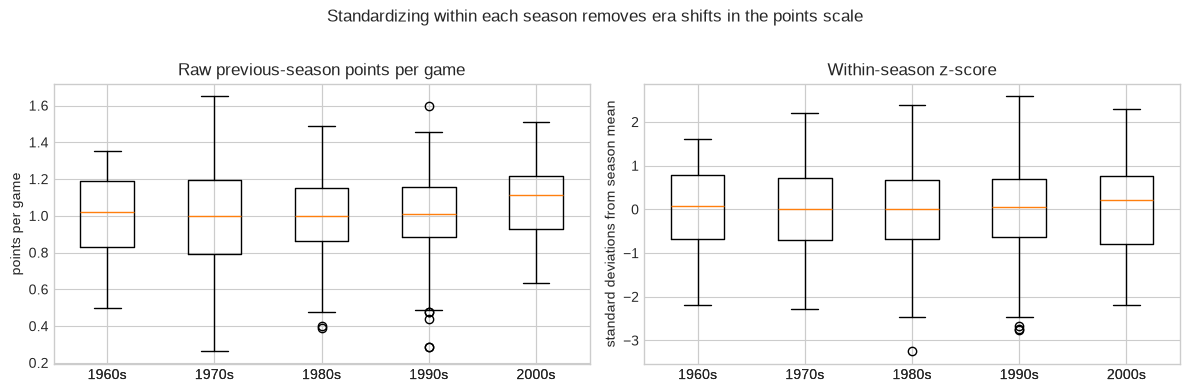

Mean raw points per game by decade: {'1960s': 1.0, '1970s': 1.002, '1980s': 1.0, '1990s': 1.006, '2000s': 1.08}


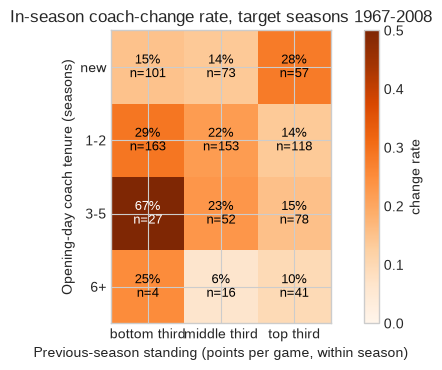

prev_ppg_z,bottom third,middle third,top third
coach_tenure_band,,,
new,0.149,0.137,0.281
1-2,0.288,0.222,0.136
3-5,0.667,0.231,0.154
6+,0.250,0.062,0.098


In [5]:
# Within-season standardization: each completed season is compared only with the teams that played it.
Z_FEATURES = [f for f in PROFILE_FEATURES if f != 'made_playoffs']
zprof = profile[['year', 'franchID']].copy()
grouped = profile.groupby('year')[Z_FEATURES]
zprof[[f + '_z' for f in Z_FEATURES]] = ((profile[Z_FEATURES] - grouped.transform('mean')) / grouped.transform('std')).to_numpy()
prev_z = zprof.rename(columns={'year': 'prev_year'}).rename(columns={f + '_z': 'prev_' + f + '_z' for f in Z_FEATURES})
prev2_z = zprof[['year', 'franchID', 'ppg_z']].rename(columns={'year': 'prev2_year', 'ppg_z': 'prev2_ppg_z'})
frame = frame.drop(columns=[c for c in frame if c.endswith('_z')], errors='ignore')
frame = (frame.merge(prev_z, on=['prev_year', 'franchID'], how='left', validate='many_to_one')
              .merge(prev2_z, on=['prev2_year', 'franchID'], how='left', validate='many_to_one'))
frame['prev_ppg_trend'] = frame.prev_ppg_z - frame.prev2_ppg_z          # improving (+) or declining (-) team
frame['coach_log_career_games'] = np.log1p(frame.career_games)           # experience is right-skewed
frame['target_ppg_z'] = frame.groupby('year').target_ppg.transform(lambda s: (s - s.mean()) / s.std())
# Discretization with domain meaning: first season, short, established, long-serving.
frame['coach_tenure_band'] = pd.cut(frame.coach_tenure, [-1, 0, 2, 5, 100], labels=['new', '1-2', '3-5', '6+'])

dev = frame[frame.year.between(1967, TEST_YEAR - 1)]  # exploration excludes the test season
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
decade = (dev.prev_year // 10 * 10).astype('Int64').astype(str) + 's'
order = sorted(decade.dropna().unique())
for ax, column, title in [(axes[0], 'prev_ppg', 'Raw previous-season points per game'),
                          (axes[1], 'prev_ppg_z', 'Within-season z-score')]:
    data = [dev.loc[decade.eq(d), column].dropna() for d in order]
    ax.boxplot(data, tick_labels=order)
    ax.set_title(title)
axes[0].set_ylabel('points per game'); axes[1].set_ylabel('standard deviations from season mean')
plt.suptitle('Standardizing within each season removes era shifts in the points scale', y=1.02)
plt.tight_layout(); plt.show()
print('Mean raw points per game by decade:', dev.groupby(decade).prev_ppg.mean().round(3).to_dict())

standing = pd.qcut(dev.prev_ppg_z, 3, labels=['bottom third', 'middle third', 'top third'])
rate = dev.pivot_table(index='coach_tenure_band', columns=standing, values='target_coach_change', aggfunc='mean', observed=False)
count = dev.pivot_table(index='coach_tenure_band', columns=standing, values='target_coach_change', aggfunc='size', observed=False)
fig, ax = plt.subplots(figsize=(7, 3.8))
image = ax.imshow(rate.to_numpy(dtype=float), cmap='Oranges', vmin=0, vmax=0.5)
ax.set_xticks(range(3), rate.columns); ax.set_yticks(range(len(rate)), rate.index)
for i in range(rate.shape[0]):
    for j in range(rate.shape[1]):
        ax.text(j, i, f'{rate.iat[i, j]:.0%}\nn={count.iat[i, j]}', ha='center', va='center', fontsize=9, color='white' if rate.iat[i, j] > 0.35 else 'black')
ax.set_xlabel('Previous-season standing (points per game, within season)'); ax.set_ylabel('Opening-day coach tenure (seasons)')
ax.set_title('In-season coach-change rate, target seasons 1967-2008')
plt.colorbar(image, ax=ax, label='change rate'); plt.tight_layout(); plt.show()
display(rate.round(3))

**What we got:**
- Mean raw points per game is about 1.00 from the 1960s to the 1990s but 1.08 in the 2000s, because overtime and shootout losses earn a point. Raw values are therefore not comparable across eras; within-season z-scores are centred on 0 in every decade.
- The coach-change rate depends on **both** tenure and standing. Established coaches (3–5 seasons) of bottom-third teams had the highest rate: 67%, about 18 of 27 teams. Long-serving coaches (6+) at middle or top teams rarely changed (6–10%). New coaches at top-third teams also changed often (28%, about 16 of 57); these include first-time coaches who inherited contenders.
- Some cells are small (6+ tenure at a bottom-third team has only 4 teams), so these are descriptive patterns, not causal claims. The interaction suggests trees or interaction terms are worth testing in modeling.

## 6. Outliers

**What we want to do:** Detect outliers three ways:
- **univariate:** |z| > 3 within a season
- **target:** IQR rule on target points per game
- **multivariate:** Isolation Forest, fitted on training seasons only

Then discuss them with hockey knowledge and treat them with rules that do not learn from the data.

Feature values beyond 3 within-season standard deviations (target seasons 1967-2008):


,prev_playoff_series_won_z,prev_all_stars_z,prev_pim_pg_z,prev_top3_points_share_z,prev_pythag_z,prev_gf_pg_z,prev_ga_pg_z,prev_gd_pg_z,prev_ppg_z,prev_home_edge_z,prev_pk_pct_z,prev_roster_age_z,prev_players_used_z,prev_late_form_z
rows,15,10,5,3,2,2,2,2,1,1,1,1,1,1


IQR target outliers: 1 of 908


,year,name,games,target_points,target_ppg_z,has_prev
737,1989,Quebec Nordiques,80,31,-3.25,1


Most anomalous prior-season profiles (Isolation Forest):


,year,name,prev_year,prev_games,prev_ppg_z,prev_gd_pg_z,prev_luck_z,prev_save_pct_z,prev_late_form_z,target_ppg_z
758,1990,Quebec Nordiques,1989.0,80.0,-3.25,-3.28,-2.29,-2.27,-0.79,-2.04
693,1987,Philadelphia Flyers,1986.0,80.0,1.64,1.82,0.33,2.53,-1.88,0.33
851,1994,Ottawa Senators,1993.0,84.0,-2.74,-3.32,0.56,-2.74,-0.06,-2.34
1215,2008,Detroit Red Wings,2007.0,82.0,2.29,2.53,-0.70,0.01,-1.56,1.49
685,1987,Edmonton Oilers,1986.0,80.0,2.14,2.46,1.01,0.14,-0.77,1.26
643,1985,Edmonton Oilers,1984.0,80.0,1.53,1.49,1.46,1.12,-2.48,1.98
996,2000,Atlanta Thrashers,1999.0,82.0,-2.76,-2.85,-0.55,-2.56,-1.11,-1.48
486,1977,Montreal Canadiens,1976.0,80.0,2.21,2.49,-0.65,NaN,1.01,1.96
1165,2006,Ottawa Senators,2005.0,82.0,1.31,2.31,-1.77,1.28,-1.17,0.84
664,1986,Edmonton Oilers,1985.0,80.0,1.98,1.76,2.42,0.96,0.10,2.14


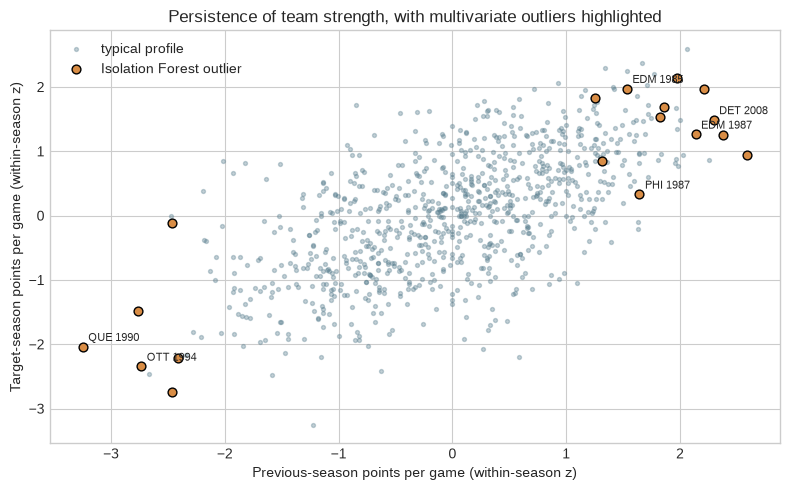

Rows whose lag season had < 80% of the target season games: {1918.0: 3, 1994.0: 26}


In [6]:
from sklearn.ensemble import IsolationForest
PREV_Z = ['prev_' + f + '_z' for f in Z_FEATURES]
dev = frame[frame.year.between(1967, TEST_YEAR - 1)].copy()
# 1) Univariate: |z| > 3 inside a season is extreme relative to that season's rivals.
extreme = (dev[PREV_Z].abs() > 3).sum().sort_values(ascending=False)
print('Feature values beyond 3 within-season standard deviations (target seasons 1967-2008):')
display(extreme[extreme > 0].rename('rows').to_frame().T)
# 2) IQR rule on the target: which seasons were extreme relative to their league?
q1, q3 = dev.target_ppg_z.quantile([0.25, 0.75])
iqr_out = dev[(dev.target_ppg_z < q1 - 1.5 * (q3 - q1)) | (dev.target_ppg_z > q3 + 1.5 * (q3 - q1))]
print(f'IQR target outliers: {len(iqr_out)} of {len(dev)}')
display(iqr_out.sort_values('target_ppg_z')[['year', 'name', 'games', 'target_points', 'target_ppg_z', 'has_prev']].round(2))
# 3) Multivariate: Isolation Forest fitted on training seasons only, scored on all development rows.
train_mask = dev.year.lt(VALIDATION_YEARS[0]) & dev.has_prev.eq(1)
X_iso = dev[PREV_Z].clip(-5, 5)
medians = X_iso[train_mask].median()
forest = IsolationForest(n_estimators=300, contamination=0.02, random_state=0).fit(X_iso[train_mask].fillna(medians))
dev['iso_outlier'] = np.where(dev.has_prev.eq(1), forest.predict(X_iso.fillna(medians)) == -1, False)
dev['iso_score'] = -forest.score_samples(X_iso.fillna(medians))
top = dev[dev.iso_outlier].sort_values('iso_score', ascending=False)
print('Most anomalous prior-season profiles (Isolation Forest):')
display(top[['year', 'name', 'prev_year', 'prev_games', 'prev_ppg_z', 'prev_gd_pg_z', 'prev_luck_z', 'prev_save_pct_z',
             'prev_late_form_z', 'target_ppg_z']].head(10).round(2))
fig, ax = plt.subplots(figsize=(8, 5))
normal = dev[~dev.iso_outlier & dev.has_prev.eq(1)]
ax.scatter(normal.prev_ppg_z, normal.target_ppg_z, s=8, alpha=0.35, color='#557B8C', label='typical profile')
ax.scatter(top.prev_ppg_z, top.target_ppg_z, s=40, color='#D98D45', edgecolor='black', label='Isolation Forest outlier')
for r in top.head(6).itertuples():
    ax.annotate(f'{r.tmID} {r.year}', (r.prev_ppg_z, r.target_ppg_z), fontsize=8, xytext=(4, 4), textcoords='offset points')
ax.set(xlabel='Previous-season points per game (within-season z)', ylabel='Target-season points per game (within-season z)',
       title='Persistence of team strength, with multivariate outliers highlighted')
ax.legend(); plt.tight_layout(); plt.show()
# Treatment: keep the rows (real seasons); cap continuous standardized rates at +-3 (a fixed, not data-fitted, threshold).
# Bounded counts (playoff series won, all-stars) are not capped: a high value is a champion, not a measurement error.
CAPPED = [c for c in PREV_Z if c not in ('prev_playoff_series_won_z', 'prev_all_stars_z')]
frame[CAPPED] = frame[CAPPED].clip(-3, 3)
frame['prev_ppg_trend'] = frame.prev_ppg_trend.clip(-3, 3)
# Flag lags whose season was much shorter than the target season's schedule (rates from fewer games are noisier).
frame['prev_short_season'] = frame.prev_games.lt(0.8 * frame.games).astype(int).where(frame.has_prev.eq(1))
print('Rows whose lag season had < 80% of the target season games:',
      frame.loc[frame.prev_short_season.eq(1)].groupby('prev_year').size().to_dict())

**What we got:**
- **Univariate:** most extreme values are bounded counts (playoff series won 15 rows, All-Stars 10): these are champions, not errors. Few continuous rates exceed 3 SD.
- **Target (IQR):** one outlier, Quebec 1989 (31 points, −3.25 SD), a real collapse.
- **Multivariate:** the Isolation Forest flags the Edmonton dynasty (1985–1987 targets), Quebec 1990 (after the collapse), Ottawa 1994 and Atlanta 2000 (second-season expansion teams), Detroit 2008 and Montreal 1977. In the scatter plot these points mostly extend the persistence trend: extreme teams tend to stay extreme. They are real seasons, so **all rows are kept**.
- **Treatment:**
  - **Capping:** continuous within-season z-scores are capped at ±3, a fixed threshold that is not fitted to data, so there is no leakage. Bounded counts are not capped.
  - **Short-season flag:** `prev_short_season` marks lags from a season with less than 80% of the target season's games. In the modern era that is the 48-game 1994 season (26 teams for 1995); 3 rows from 1918 fall outside the modeling era.

## 7. Missing values

**What we want to do:** Measure missingness in target seasons 1967–2009 and explain its cause. Then compare imputation methods with a correct experimental setup: fit each imputer on training seasons (1967–2004), hide 15% of observed validation values (2005–2008), and score how well each method recovers them. Errors are in training standard deviations.

In [7]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)  # iterative imputer may stop at max_iter; results are still compared
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.linear_model import BayesianRidge
from sklearn.ensemble import RandomForestRegressor
COACH = ['coach_new', 'coach_tenure', 'coach_log_career_games', 'career_points_pct', 'coach_rookie', 'franchise_changes_3y']
CANDIDATES = PREV_Z + ['prev_made_playoffs', 'prev_ppg_trend', 'prev_short_season'] + COACH
model_rows = frame[frame.year.between(1967, TEST_YEAR)]
missing = model_rows[CANDIDATES].isna().mean().sort_values(ascending=False)
print('Share missing in target seasons 1967-2009 (features with any missing):')
display(missing[missing > 0].round(3).rename('missing_share').to_frame().T)
# Why values are missing: each gap has a structural cause.
reasons = pd.DataFrame({
    'no previous NHL season (expansion / WHA entrant)': [int(model_rows.has_prev.eq(0).sum())],
    'save_pct: shots against not recorded before 1983': [int((model_rows.has_prev.eq(1) & model_rows.prev_save_pct_z.isna()).sum())],
    'trend: no season two back (second-season teams)': [int((model_rows.has_prev.eq(1) & model_rows.prev_ppg_trend.isna()).sum())],
    'career_points_pct: first-time head coach': [int(model_rows.career_points_pct.isna().sum())]}, index=['rows']).T
display(reasons)
entrants = frame[frame.year.between(1967, VALIDATION_YEARS[0] - 1) & frame.has_prev.eq(0)]
print(f'New entrants in training seasons: {len(entrants)}; mean target z {entrants.target_ppg_z.mean():.2f} '
      f'(league average = 0). Filling their lags with an average value would call them average teams.')

# Imputation experiment with a correct setup: fit on training seasons, score on masked validation values.
EXP = PREV_Z + ['prev_ppg_trend', 'coach_log_career_games', 'career_points_pct', 'coach_tenure']
train = frame[frame.year.between(1967, VALIDATION_YEARS[0] - 1) & frame.has_prev.eq(1)][EXP]
valid = frame[frame.year.isin(VALIDATION_YEARS) & frame.has_prev.eq(1)][EXP]
rng = np.random.default_rng(0)
observed = valid.notna().to_numpy()
mask = observed & (rng.random(valid.shape) < 0.15)
valid_masked = valid.mask(mask)
scale = train.std().to_numpy()
methods = {'mean': SimpleImputer(strategy='mean'), 'median': SimpleImputer(strategy='median'),
           'KNN (k=10)': KNNImputer(n_neighbors=10),
           'iterative: Bayesian ridge regression': IterativeImputer(BayesianRidge(), max_iter=20, random_state=0),
           'iterative: random forest': IterativeImputer(RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=0),
                                                        max_iter=5, random_state=0)}
scores = []
for name, imputer in methods.items():
    if name.startswith('KNN'):  # distance-based: put features on a common scale learned from training rows
        mu, sd = train.mean(), train.std()
        filled = imputer.fit(((train - mu) / sd).to_numpy()).transform(((valid_masked - mu) / sd).to_numpy()) * sd.to_numpy() + mu.to_numpy()
    else:
        filled = imputer.fit(train.to_numpy()).transform(valid_masked.to_numpy())
    errors = ((filled - valid.to_numpy()) / scale)[mask]
    scores.append({'method': name, 'masked_values': int(mask.sum()), 'rmse_in_training_sd': round(float(np.sqrt(np.mean(errors ** 2))), 3)})
imputation_scores = pd.DataFrame(scores).sort_values('rmse_in_training_sd')
display(imputation_scores)
imputation_scores.to_csv(OUT / 'imputation_experiment.csv', index=False)

Share missing in target seasons 1967-2009 (features with any missing):


,prev_save_pct_z,career_points_pct,prev_ppg_trend,prev_ppg_z,prev_pythag_z,prev_luck_z,prev_pp_pct_z,prev_pk_pct_z,prev_pim_pg_z,prev_gf_pg_z,prev_ga_pg_z,prev_gd_pg_z,prev_late_form_z,prev_home_edge_z,prev_shorthanded_net_pg_z,prev_playoff_series_won_z,prev_top3_points_share_z,prev_starter_minutes_share_z,prev_roster_age_z,prev_players_used_z,prev_made_playoffs,prev_all_stars_z,coach_new,prev_short_season,franchise_changes_3y
missing_share,0.303,0.133,0.053,0.027,0.027,0.027,0.027,0.027,0.027,0.027,0.027,0.027,0.027,0.027,0.027,0.027,0.027,0.027,0.027,0.027,0.027,0.027,0.027,0.027,0.027


,rows
no previous NHL season (expansion / WHA entrant),25
save_pct: shots against not recorded before 1983,259
trend: no season two back (second-season teams),25
career_points_pct: first-time head coach,125


New entrants in training seasons: 25; mean target z -1.14 (league average = 0). Filling their lags with an average value would call them average teams.


,method,masked_values,rmse_in_training_sd
4,iterative: random forest,429,0.761
3,iterative: Bayesian ridge regression,429,0.788
2,KNN (k=10),429,0.825
0,mean,429,0.969
1,median,429,0.972


**What we got:**
- **Every gap is structural:** 25 new-entrant rows have no previous season, save percentage is missing for 259 rows whose lag predates 1983, 25 rows lack a second season for the trend, and 125 first-time head coaches have no career record.
- **New entrants are not average:** their mean first-season result is −1.14 SD. Filling their lags with the mean would call them average teams; the `has_prev` indicator lets models treat them separately.
- **Imputation experiment (429 hidden values):** iterative imputation with random forests had the lowest error (0.761), then iterative Bayesian ridge regression (0.788), KNN (0.825), mean (0.969) and median (0.972). Model-based imputation recovers values clearly better than simple filling.
- **Decision:** the modeling notebook uses iterative imputation plus missing-value indicators **inside each training fold**. The exported table keeps missing values as missing.

## 8. Redundant features

**What we want to do:** Find features that carry the same information, using correlations on training seasons only (no target involved). Remove them systematically: walk through the features in a fixed domain-priority order and drop any feature with |r| > 0.9 to one already kept.

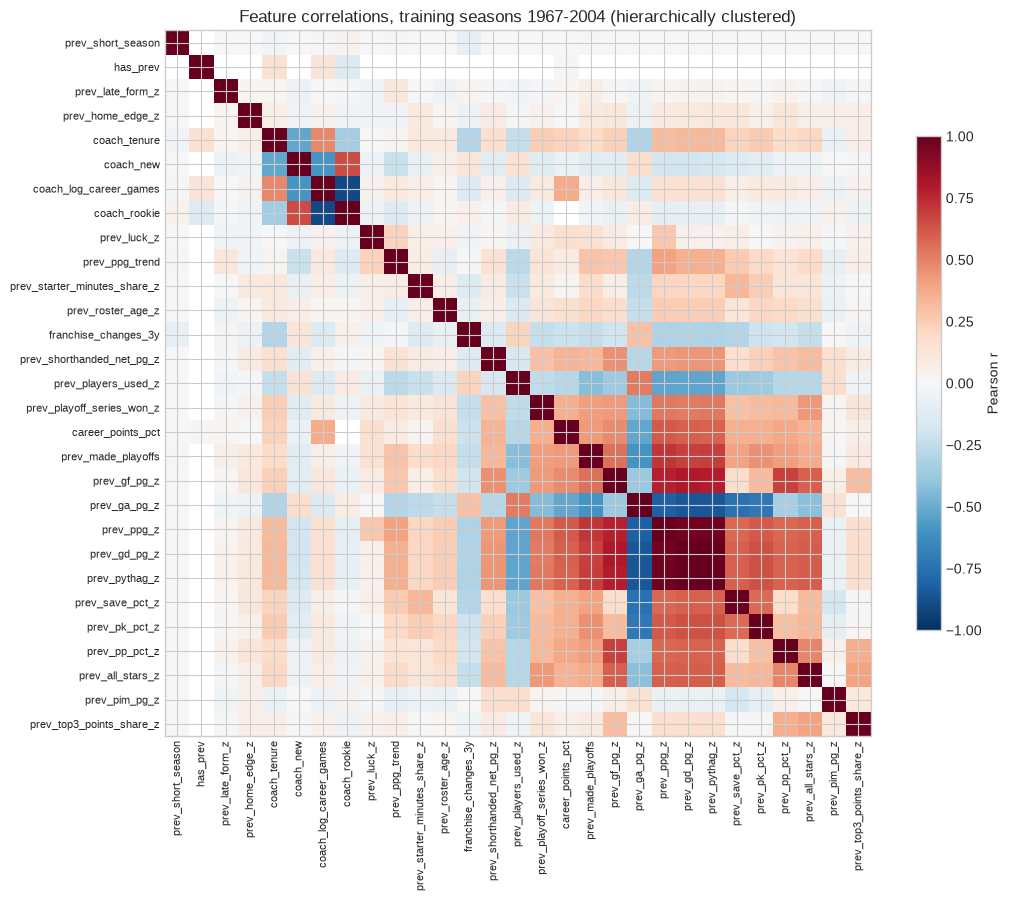

,dropped,redundant_with,abs_r
0,prev_gd_pg_z,prev_ppg_z,0.968
1,prev_pythag_z,prev_ppg_z,0.969
2,coach_rookie,coach_log_career_games,0.900


Strongest remaining correlations among kept features:


prev_ppg_z    prev_ga_pg_z          0.816
              prev_gf_pg_z          0.779
prev_ga_pg_z  prev_save_pct_z       0.743
              prev_pk_pct_z         0.715
prev_ppg_z    prev_made_playoffs    0.712
prev_gf_pg_z  prev_pp_pct_z         0.683
dtype: float64

26 features kept: ['prev_ppg_z', 'prev_luck_z', 'prev_gf_pg_z', 'prev_ga_pg_z', 'prev_save_pct_z', 'prev_pp_pct_z', 'prev_pk_pct_z', 'prev_shorthanded_net_pg_z', 'prev_pim_pg_z', 'prev_home_edge_z', 'prev_late_form_z', 'prev_ppg_trend', 'prev_made_playoffs', 'prev_playoff_series_won_z', 'prev_all_stars_z', 'prev_top3_points_share_z', 'prev_roster_age_z', 'prev_players_used_z', 'prev_starter_minutes_share_z', 'prev_short_season', 'coach_new', 'coach_tenure', 'coach_log_career_games', 'career_points_pct', 'franchise_changes_3y', 'has_prev']


In [8]:
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
# Priority = domain order of preference when two features carry the same information (most interpretable first).
PRIORITY = ['prev_ppg_z', 'prev_gd_pg_z', 'prev_pythag_z', 'prev_luck_z', 'prev_gf_pg_z', 'prev_ga_pg_z', 'prev_save_pct_z',
            'prev_pp_pct_z', 'prev_pk_pct_z', 'prev_shorthanded_net_pg_z', 'prev_pim_pg_z', 'prev_home_edge_z', 'prev_late_form_z',
            'prev_ppg_trend', 'prev_made_playoffs', 'prev_playoff_series_won_z', 'prev_all_stars_z', 'prev_top3_points_share_z',
            'prev_roster_age_z', 'prev_players_used_z', 'prev_starter_minutes_share_z', 'prev_short_season',
            'coach_new', 'coach_tenure', 'coach_log_career_games', 'coach_rookie', 'career_points_pct', 'franchise_changes_3y', 'has_prev']
assert set(PRIORITY) == set(CANDIDATES) | {'has_prev'}
train_rows = frame[frame.year.between(1967, VALIDATION_YEARS[0] - 1)]   # training seasons only; no target used
corr = train_rows[PRIORITY].corr()
order = leaves_list(linkage(squareform(1 - corr.abs().fillna(0).to_numpy(), checks=False), 'average'))
ordered = corr.iloc[order, order]
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(ordered, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(ordered)), ordered.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(ordered)), ordered.index, fontsize=8)
ax.set_title('Feature correlations, training seasons 1967-2004 (hierarchically clustered)')
plt.colorbar(image, ax=ax, shrink=0.7, label='Pearson r'); plt.tight_layout(); plt.show()
kept, dropped = [], []
for feature in PRIORITY:
    partner = next((k for k in kept if abs(corr.loc[feature, k]) > 0.9), None)
    if partner is None:
        kept.append(feature)
    else:
        dropped.append({'dropped': feature, 'redundant_with': partner, 'abs_r': round(abs(corr.loc[feature, partner]), 3)})
display(pd.DataFrame(dropped))
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
print('Strongest remaining correlations among kept features:')
display(pairs[pairs.index.map(lambda p: p[0] in kept and p[1] in kept)].abs().sort_values(ascending=False).head(6).round(3))
FEATURES = kept
print(len(FEATURES), 'features kept:', FEATURES)

**What we got:**
- **Dropped:** goal difference per game (r = 0.968 with points per game), Pythagorean expectation (r = 0.969 with points per game) and the rookie-coach flag (r = 0.900 with log career games).
- **Kept:** "luck" stays: it is the difference between points and goal-based expectation, so it carries information neither feature has alone.
- **Remaining pairs:** strong but distinct pairs remain (for example points vs goals against 0.816, goals against vs save percentage 0.743). They describe different hockey mechanisms and are left to feature selection inside the modeling folds.
- **Result:** 26 features remain. The clustered heatmap shows blocks for scoring, defence and goaltending, playoff success and coaching.

## 9. Development sampling and choice of training era

**What we want to do:**
- **Grow the sample:** start with a very small training sample (1 season) and grow it to 38 seasons, scoring each validation season 2005–2008 with an expanding window.
- **Models:** deliberately simple, fast pipelines. Ridge regression predicts points-per-game z (scored by within-season Spearman correlation), and balanced logistic regression predicts coach change (scored by PR-AUC). Imputation and scaling are fitted inside each window only.
- **Baselines:** "same order as last season" for ranking, and prevalence for coach change. The test season is not used.

,seasons_in_window,first_training_season_for_2005,mean_training_rows,ranking_spearman_mean,ranking_spearman_sd,coach_pr_auc
0,1,2003,30,0.361,0.108,0.227
1,2,2002,60,0.425,0.035,0.200
2,3,2001,90,0.391,0.050,0.198
3,5,1999,149,0.443,0.031,0.191
4,8,1996,232,0.428,0.062,0.204
5,12,1992,336,0.432,0.066,0.201
6,16,1988,427,0.421,0.061,0.206
7,20,1984,511,0.430,0.050,0.203
8,25,1979,616,0.445,0.040,0.193
9,30,1974,710,0.455,0.045,0.201


Baselines on the same validation seasons: persistence Spearman 0.514; random-ranking coach PR-AUC = prevalence 0.175 (21 changes in 120 team-seasons)


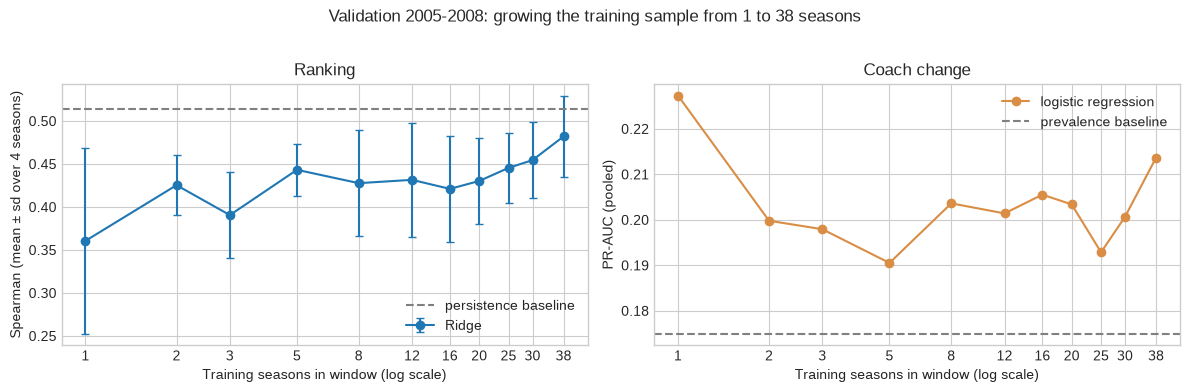

,feature_set,2005,2006,2007,2008,mean
0,previous points only,0.457,0.558,0.485,0.554,0.514
1,points + luck + trend,0.490,0.611,0.495,0.474,0.517
2,all 26 kept features,0.488,0.525,0.509,0.417,0.485


In [9]:
from scipy.stats import spearmanr
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import average_precision_score
# Start with a tiny training sample (1 season) and grow it, scoring each validation season with expanding windows.
# Simple, fast pipelines; imputation and scaling are fitted inside each training window only.
def ranking_model():
    return make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler(), Ridge(alpha=10))
def coach_model():
    return make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler(),
                         LogisticRegression(C=0.1, class_weight='balanced', max_iter=2000))
WINDOWS = [1, 2, 3, 5, 8, 12, 16, 20, 25, 30, 38]
results = []
for k in WINDOWS:
    spearman, coach_scores, coach_truth, train_sizes = [], [], [], []
    for v in VALIDATION_YEARS:
        past = [s for s in seasons if s < v][-k:]
        tr = frame[frame.year.isin(past)]
        te = frame[frame.year.eq(v)]
        reg = ranking_model().fit(tr[FEATURES], tr.target_ppg_z)
        spearman.append(spearmanr(reg.predict(te[FEATURES]), te.target_ppg_z).statistic)
        clf = coach_model().fit(tr[FEATURES], tr.target_coach_change)
        coach_scores.extend(clf.predict_proba(te[FEATURES])[:, 1]); coach_truth.extend(te.target_coach_change)
        train_sizes.append(len(tr))
    results.append({'seasons_in_window': k, 'first_training_season_for_2005': [s for s in seasons if s < 2005][-k:][0],
                    'mean_training_rows': int(np.mean(train_sizes)), 'ranking_spearman_mean': np.mean(spearman),
                    'ranking_spearman_sd': np.std(spearman), 'coach_pr_auc': average_precision_score(coach_truth, coach_scores)})
growth = pd.DataFrame(results)
validation = frame[frame.year.isin(VALIDATION_YEARS)]
persistence = np.mean([spearmanr(g.prev_ppg_z.fillna(-3), g.target_ppg_z).statistic for _, g in validation.groupby('year')])
prevalence = validation.target_coach_change.mean()
display(growth.round(3))
print(f'Baselines on the same validation seasons: persistence Spearman {persistence:.3f}; '
      f'random-ranking coach PR-AUC = prevalence {prevalence:.3f} ({int(validation.target_coach_change.sum())} changes in {len(validation)} team-seasons)')
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].errorbar(growth.seasons_in_window, growth.ranking_spearman_mean, yerr=growth.ranking_spearman_sd, marker='o', capsize=3, label='Ridge')
axes[0].axhline(persistence, color='grey', ls='--', label='persistence baseline')
axes[0].set(xscale='log', xlabel='Training seasons in window (log scale)', ylabel='Spearman (mean ± sd over 4 seasons)', title='Ranking')
axes[1].plot(growth.seasons_in_window, growth.coach_pr_auc, marker='o', color='#D98D45', label='logistic regression')
axes[1].axhline(prevalence, color='grey', ls='--', label='prevalence baseline')
axes[1].set(xscale='log', xlabel='Training seasons in window (log scale)', ylabel='PR-AUC (pooled)', title='Coach change')
for ax in axes:
    ax.set_xticks(WINDOWS, WINDOWS); ax.legend()
plt.suptitle('Validation 2005-2008: growing the training sample from 1 to 38 seasons', y=1.02); plt.tight_layout(); plt.show()
growth.to_csv(OUT / 'development_sample_growth.csv', index=False)
# Same full window (target seasons 1967 onward), different feature sets: does every feature help?
feature_sets = {'previous points only': ['prev_ppg_z', 'has_prev'],
                'points + luck + trend': ['prev_ppg_z', 'prev_luck_z', 'prev_ppg_trend', 'has_prev'],
                f'all {len(FEATURES)} kept features': FEATURES}
rows = []
for name, cols in feature_sets.items():
    per_season = []
    for v in VALIDATION_YEARS:
        tr, te = frame[frame.year.between(1967, v - 1)], frame[frame.year.eq(v)]
        per_season.append(spearmanr(ranking_model().fit(tr[cols], tr.target_ppg_z).predict(te[cols]), te.target_ppg_z).statistic)
    rows.append({'feature_set': name, **{str(v): round(s, 3) for v, s in zip(VALIDATION_YEARS, per_season)}, 'mean': round(np.mean(per_season), 3)})
display(pd.DataFrame(rows))

**What we got:**
- **Ranking:** improves with more data, from Spearman 0.361 with 1 season to 0.482 with 38 (back to the late 1960s). The noise between seasons (±0.03–0.11) is large relative to these gains.
- **The baseline is strong:** persistence scores 0.514. A Ridge on previous points alone reproduces it exactly, adding luck and trend reaches 0.517, but all 26 features fall to 0.485 (0.417 in 2008). Extra weak features add noise, so **feature selection is necessary** in modeling.
- **Coach change is hard:** PR-AUC stays around 0.19–0.23 at every window size, against a prevalence baseline of 0.175 (21 changes in 120 validation team-seasons).
- **Decision:** train on target seasons from **1967**. That is the largest window, the start of the expansion era, and the first season with complete special-teams data. It gives the best ranking score, and coach performance does not favour a shorter window.

## 10. Export the modeling table

**What we want to do:** Save one row per NHL team-season from 1967 to 2009 with identifiers, the 26 features, the tenure band, the targets and a `split` column (train 1967–2003, validation 2005–2008, test 2009). Assert that no feature comes from the target season, and save a feature dictionary.

In [10]:
TRAIN_START = 1967
model_table = frame[frame.year.between(TRAIN_START, TEST_YEAR)].copy()
model_table['split'] = np.select([model_table.year.lt(VALIDATION_YEARS[0]), model_table.year.isin(VALIDATION_YEARS)],
                                 ['train', 'validation'], 'test')
IDS = ['year', 'lgID', 'tmID', 'franchID', 'name', 'confID', 'divID', 'games', 'league_teams', 'prev_year', 'prev_gap', 'split']
TARGETS = ['target_ppg', 'target_ppg_z', 'target_points', 'target_rank_league', 'target_rank_division', 'target_coach_change']
EXTRA = ['coach_tenure_band']  # discretized view for interpretable models and plots
# Leakage guards: features never come from the target season's results.
assert not set(FEATURES) & set(TARGETS) and not any(c.startswith('target') for c in FEATURES)
assert (model_table.prev_year.dropna() < model_table.year[model_table.prev_year.notna()]).all()
assert model_table.loc[model_table.split.eq('test'), 'prev_year'].max() == TEST_YEAR - 1
assert not model_table.duplicated(['year', 'franchID']).any()
model_table[IDS + FEATURES + EXTRA + TARGETS].to_csv(PROCESSED / 'modeling_table.csv', index=False)

DESCRIPTIONS = {
    'prev_ppg_z': ('Teams', 'points per game'), 'prev_luck_z': ('Teams', 'points share minus Pythagorean expectation (shootout goals removed)'),
    'prev_gf_pg_z': ('Teams', 'goals for per game, excluding shootout goals'), 'prev_ga_pg_z': ('Teams', 'goals against per game, excluding shootout goals'),
    'prev_save_pct_z': ('Goalies', 'team save percentage 1 - GA/SA (from 1983)'), 'prev_pp_pct_z': ('Teams', 'power-play conversion PPG/PPC'),
    'prev_pk_pct_z': ('Teams', 'penalty-kill success 1 - PKG/PKC'), 'prev_shorthanded_net_pg_z': ('Teams', 'short-handed goals for minus against per game'),
    'prev_pim_pg_z': ('Teams', 'penalty minutes per game'), 'prev_home_edge_z': ('TeamSplits', 'home win share minus road win share'),
    'prev_late_form_z': ('TeamSplits', 'Feb-Apr win share minus season win share'),
    'prev_ppg_trend': ('Teams', 'points-per-game z change between the two previous seasons'),
    'prev_made_playoffs': ('SeriesPost', 'reached the playoffs (0/1)'), 'prev_playoff_series_won_z': ('SeriesPost', 'playoff series won'),
    'prev_all_stars_z': ('AwardsPlayers + Scoring', 'First/Second Team All-Stars credited to main team'),
    'prev_top3_points_share_z': ('Scoring', 'share of team points from its top 3 scorers'),
    'prev_roster_age_z': ('Scoring + Master', 'games-weighted roster age'), 'prev_players_used_z': ('Scoring', 'distinct skaters/goalies used'),
    'prev_starter_minutes_share_z': ('Goalies', "starting goalie's share of goalie minutes"),
    'prev_short_season': ('Teams', 'previous season had < 80% of target-season games (1994 lockout)'),
    'coach_new': ('Coaches (corrected)', 'opening-day coach differs from previous final coach'),
    'coach_tenure': ('Coaches (corrected)', 'consecutive previous seasons the opening-day coach led this franchise'),
    'coach_log_career_games': ('Coaches (corrected)', 'log(1 + regular-season games coached before season t)'),
    'career_points_pct': ('Coaches (corrected)', 'career points percentage before season t; blank for first-time coaches'),
    'franchise_changes_3y': ('Coaches (corrected)', 'in-season coach changes in the franchise over the previous 3 seasons'),
    'has_prev': ('Teams', '1 if the franchise played the previous NHL season')}
dictionary = pd.DataFrame([{'feature': f, 'source': DESCRIPTIONS[f][0], 'meaning': DESCRIPTIONS[f][1],
                            'transform': 'within-season z, capped at ±3' if f in CAPPED else ('within-season z' if f.endswith('_z') else
                                         ('difference of within-season z, capped at ±3' if f == 'prev_ppg_trend' else 'none')),
                            'available_day_before_season': 'yes', 'missing_share': round(model_table[f].isna().mean(), 3)} for f in FEATURES])
dictionary.to_csv(OUT / 'feature_dictionary.csv', index=False)
display(dictionary)
summary = model_table.groupby('split', sort=False).agg(seasons=('year', 'nunique'), first=('year', 'min'), last=('year', 'max'),
                                                         team_seasons=('tmID', 'size'), coach_changes=('target_coach_change', 'sum'),
                                                         change_rate=('target_coach_change', 'mean'))
display(summary.round(3))
print('Saved', (PROCESSED / 'modeling_table.csv').relative_to(ROOT), model_table[IDS + FEATURES + EXTRA + TARGETS].shape)

,feature,source,meaning,transform,available_day_before_season,missing_share
0,prev_ppg_z,Teams,points per game,"within-season z, capped at ±3",yes,0.027
1,prev_luck_z,Teams,points share minus Pythagorean expectation (sh...,"within-season z, capped at ±3",yes,0.027
2,prev_gf_pg_z,Teams,"goals for per game, excluding shootout goals","within-season z, capped at ±3",yes,0.027
3,prev_ga_pg_z,Teams,"goals against per game, excluding shootout goals","within-season z, capped at ±3",yes,0.027
4,prev_save_pct_z,Goalies,team save percentage 1 - GA/SA (from 1983),"within-season z, capped at ±3",yes,0.303
5,prev_pp_pct_z,Teams,power-play conversion PPG/PPC,"within-season z, capped at ±3",yes,0.027
6,prev_pk_pct_z,Teams,penalty-kill success 1 - PKG/PKC,"within-season z, capped at ±3",yes,0.027
7,prev_shorthanded_net_pg_z,Teams,short-handed goals for minus against per game,"within-season z, capped at ±3",yes,0.027
8,prev_pim_pg_z,Teams,penalty minutes per game,"within-season z, capped at ±3",yes,0.027
9,prev_home_edge_z,TeamSplits,home win share minus road win share,"within-season z, capped at ±3",yes,0.027


,seasons,first,last,team_seasons,coach_changes,change_rate
split,,,,,,
train,37,1967,2003,788,170,0.216
validation,4,2005,2008,120,21,0.175
test,1,2009,2009,30,3,0.100


Saved data/processed/modeling_table.csv (938, 45)


**What we got:**
- **Saved table:** `data/processed/modeling_table.csv` has 938 rows and 45 columns. Leakage checks pass: every lag season precedes its target season, and test features come from 2008 at the latest.
- **Feature dictionary:** `reports/prep/feature_dictionary.csv` records each feature's source, meaning, transform and missing share. Save percentage (30.3%) and coach career points percentage (13.3%) have the most missing values.
- **Splits:** train has 37 seasons and 788 team-seasons (170 coach changes, 21.6%); validation has 4 seasons and 120 rows (21 changes, 17.5%); test is 2009 with 30 rows (3 changes, 10.0%). Coach changes are a minority class everywhere, and rarer in recent seasons.

## Final conclusion · what this notebook established

**Data quality.** Checks in six dimensions found the NHL data from 1967 complete, unique, valid and internally consistent. Two accuracy issues matter for modeling: team goal totals include one goal per shootout game, and Phoenix 2009 is credited to the wrong coach. The first is handled in the features (goals in play only); the second is corrected in a derived copy. One one-goal discrepancy (Detroit 2005) is documented and kept.

**Integration and features.** Seven sources were matched to franchise-seasons with a 100% match rate. Each target season gets 26 features from the previous completed season and from opening-day coaching facts, built on hockey concepts: Pythagorean expectation and luck, special teams, late form, playoff progress, roster age and star concentration, goaltending workload, All-Stars and coaching stability. The 2004 lockout is bridged explicitly (2005 uses 2003–04). WHA history is not mixed into NHL lags.

**Transformation, outliers and missing data.** Within-season standardization makes eras comparable. Outliers are real seasons; they are kept, continuous rates are capped at ±3 SD, and the 48-game 1994 lag is flagged. Missing values are structural, and iterative (regression and random-forest) imputation recovered masked values best. Imputation is therefore applied inside the modeling folds, together with a new-entrant indicator.

**Knowledge gained.**
- **Team strength persists:** last season's points per game is already a strong ranking baseline (validation Spearman 0.514). Adding many weak features hurt, so feature selection is needed.
- **Coach changes are driven by an interaction:** coaches with a few seasons in charge of bottom-third teams are most at risk. Single features are only weakly related to coach changes, so the classification task will be difficult and must be judged against the prevalence baseline.

**Next: modeling notebook.**
1. Expanding-window validation over 2005–2008, with 2009 kept untouched until the end.
2. Baselines: persistence for ranking; majority and prevalence for coach change.
3. Inside each fold: iterative imputation, scaling, class weights and SMOTE for the minority class, and filter plus wrapper feature selection.
4. At least four algorithms with different biases, with systematic hyperparameter search.
5. Spearman and rank error for ranking; PR-AUC, precision, recall and F1 for coach change.
6. Statistical significance tests across validation seasons, overfitting analysis, feature importance and interpretation of white-box models.

Task (c) remains unannounced.